

# Source localization with MNE, dSPM, sLORETA, and eLORETA

The aim of this tutorial is to teach you how to compute and apply a linear
minimum-norm inverse method on evoked/raw/epochs data.


In [1]:
# Authors: The MNE-Python contributors.
# License: BSD-3-Clause
# Copyright the MNE-Python contributors.

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import mne
from mne.datasets import sample
from mne.minimum_norm import apply_inverse, make_inverse_operator

Process MEG data



In [3]:
data_path = sample.data_path()
raw_fname = data_path / "MEG" / "sample" / "sample_audvis_filt-0-40_raw.fif"

raw = mne.io.read_raw_fif(raw_fname)  # already has an average reference
events = mne.find_events(raw, stim_channel="STI 014")

event_id = dict(aud_l=1)  # event trigger and conditions
tmin = -0.2  # start of each epoch (200ms before the trigger)
tmax = 0.5  # end of each epoch (500ms after the trigger)
raw.info["bads"] = ["MEG 2443", "EEG 053"]  # mark known bad channels
baseline = (None, 0)  # means from the first instant to t = 0
reject = dict(grad=4000e-13, mag=4e-12, eog=150e-6)

epochs = mne.Epochs(
    raw,
    events,
    event_id,
    tmin,
    tmax,
    proj=True,
    picks=("meg", "eog"),
    baseline=baseline,
    reject=reject,
)

Opening raw data file C:\Users\alber\mne_data\MNE-sample-data\MEG\sample\sample_audvis_filt-0-40_raw.fif...
    Read a total of 4 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
        Average EEG reference (1 x 60)  idle
    Range : 6450 ... 48149 =     42.956 ...   320.665 secs
Ready.
Finding events on: STI 014
319 events found on stim channel STI 014
Event IDs: [ 1  2  3  4  5 32]
Not setting metadata
72 matching events found
Setting baseline interval to [-0.19979521315838786, 0.0] s
Applying baseline correction (mode: mean)
Created an SSP operator (subspace dimension = 3)
3 projection items activated


## Compute regularized noise covariance
For more details see `tut-compute-covariance`.



Loading data for 72 events and 106 original time points ...
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on MAG : ['MEG 1711']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
    Rejecting  epoch based on EOG : ['EOG 061']
17 bad epochs dropped
    Created an SSP operator (subspace dimension = 3)
    Setting small MEG eigenvalues to zero (witho

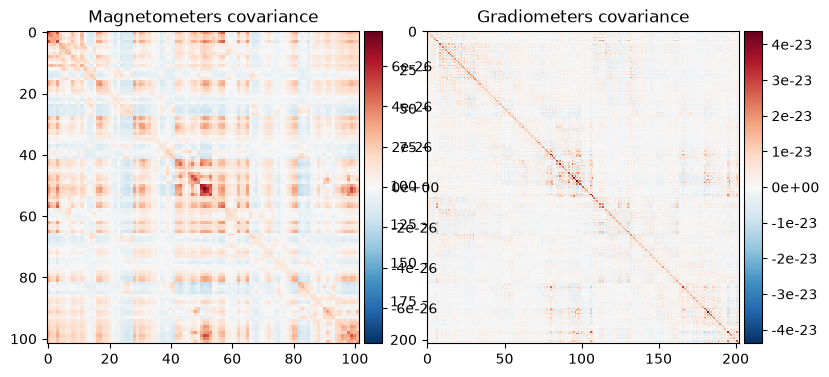

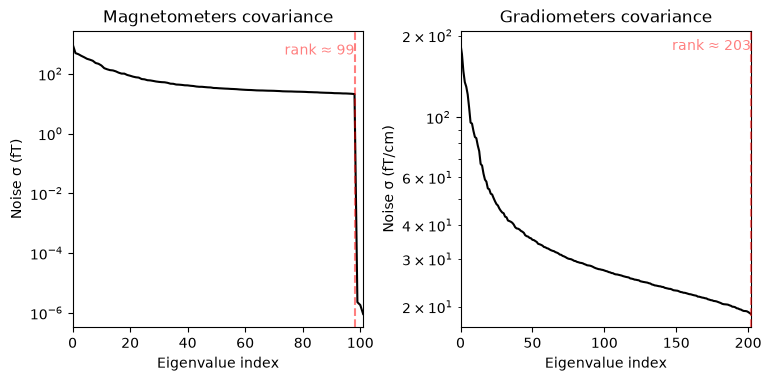

In [4]:
noise_cov = mne.compute_covariance(
    epochs, tmax=0.0, method=["shrunk", "empirical"], rank=None, verbose=True
)

fig_cov, fig_spectra = mne.viz.plot_cov(noise_cov, raw.info)

## Compute the evoked response
Let's just use the MEG channels for simplicity.



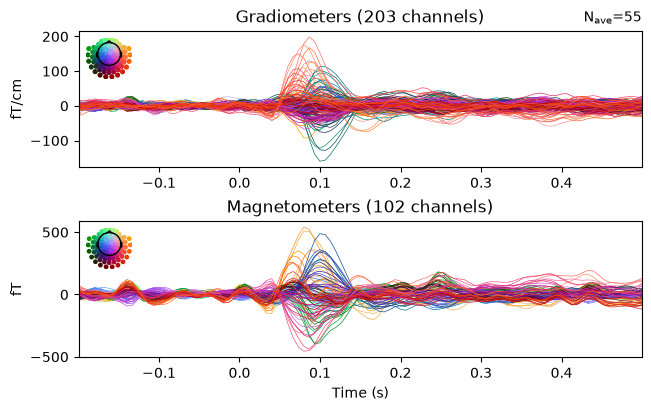

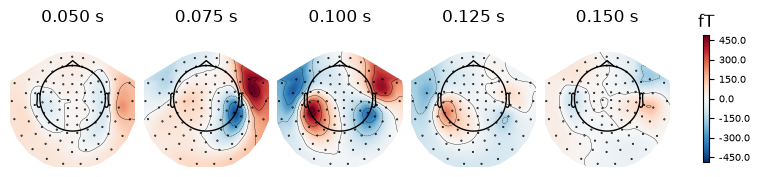

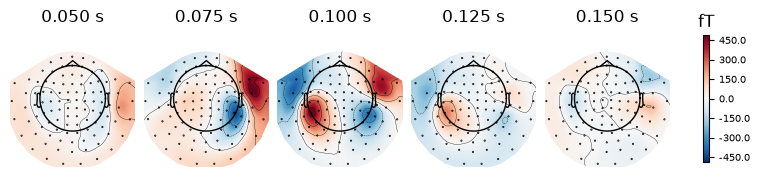

In [5]:
evoked = epochs.average().pick("meg")
evoked.plot(time_unit="s")
evoked.plot_topomap(times=np.linspace(0.05, 0.15, 5), ch_type="mag")

It's also a good idea to look at whitened data:



NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Computing rank from covariance with rank=None
    Using tolerance 1.6e-13 (2.2e-16 eps * 203 dim * 3.5  max singular value)
    Estimated rank (grad): 203
    GRAD: rank 203 computed from 203 data channels with 0 projectors
Computing rank from covariance with rank=None
    Using tolerance 2.2e-14 (2.2e-16 eps * 102 dim * 0.97  max singular value)
    Estimated rank (mag): 99
    MAG: rank 99 computed from 102 data channels with 3 projectors
    Created an SSP operator (subspace dimension = 3)
Computing rank from covariance with rank={'grad': 203, 'mag': 99, 'meg': 302}
    Setting small MEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 302 (3 small eigenvalues omitted)


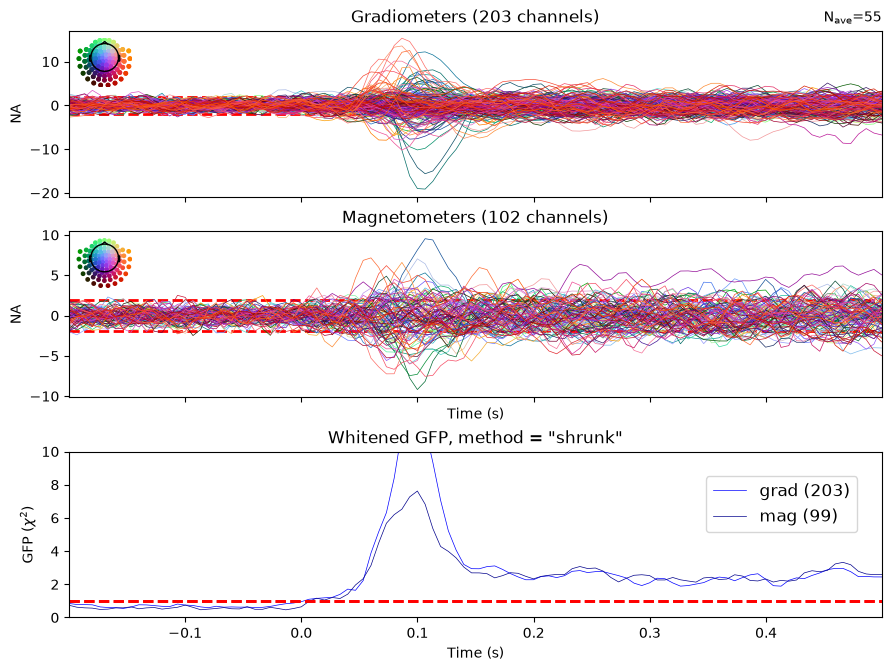

In [6]:
evoked.plot_white(noise_cov, time_unit="s")
del epochs, raw  # to save memory

## Inverse modeling: MNE/dSPM on evoked and raw data
Here we first read the forward solution. You will likely need to compute
one for your own data -- see `tut-forward` for information on how
to do it.



In [7]:
fname_fwd = data_path / "MEG" / "sample" / "sample_audvis-meg-oct-6-fwd.fif"
fwd = mne.read_forward_solution(fname_fwd)

Reading forward solution from C:\Users\alber\mne_data\MNE-sample-data\MEG\sample\sample_audvis-meg-oct-6-fwd.fif...
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    Reading a source space...
    Computing patch statistics...
    Patch information added...
    Distance information added...
    [done]
    2 source spaces read
    Desired named matrix (kind = 3523 (FIFF_MNE_FORWARD_SOLUTION_GRAD)) not available
    Read MEG forward solution (7498 sources, 306 channels, free orientations)
    Source spaces transformed to the forward solution coordinate frame


Next, we make an MEG inverse operator.



In [8]:
inverse_operator = make_inverse_operator(
    evoked.info, fwd, noise_cov, loose=0.2, depth=0.8
)
del fwd

Converting forward solution to surface orientation
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
info["bads"] and noise_cov["bads"] do not match, excluding bad channels from both
Computing inverse operator with 305 channels.
    305 out of 306 channels remain after picking
Selected 305 channels
Creating the depth weighting matrix...
    203 planar channels
    limit = 7265/7498 = 10.037795
    scale = 2.52065e-08 exp = 0.8
Applying loose dipole orientations to surface source spaces: 0.2
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 3)
Computing rank from covariance with rank=None
    Using tolerance 2.9e-13 (2.2e-16 eps * 305 dim * 4.2  max singular value)
    Estimated rank (mag + grad): 302
    MEG: rank 302 computed from 305 data channels with 3 projectors
    Setting small MEG eigenvalues to zero (without PCA)
Creating the source co

<div class="alert alert-info"><h4>Note</h4><p>You can write the inverse operator to disk with:

```
from mne.minimum_norm import write_inverse_operator
write_inverse_operator(
    "sample_audvis-meg-oct-6-inv.fif", inverse_operator
)</p></div>
```
## Compute inverse solution
We can use this to compute the inverse solution and obtain source time
courses:



In [34]:
method = "dSPM"  # could choose dSPM, sLORETA, or eLORETA instead
snr = 3.0
lambda2 = 1.0 / snr**2
stc, residual = apply_inverse(
    evoked,
    inverse_operator,
    lambda2,
    method=method,
    pick_ori=None,
    return_residual=True,
    verbose=True,
)

Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 55
    Created the regularized inverter
    Created an SSP operator (subspace dimension = 3)
    Created the whitener using a noise covariance matrix with rank 302 (3 small eigenvalues omitted)
    Computing noise-normalization factors (dSPM)...
[done]
Applying inverse operator to "aud_l"...
    Picked 305 channels from the data
    Computing inverse...
    Eigenleads need to be weighted ...
    Computing residual...
    Explained  66.0% variance
    Combining the current components...
    dSPM...
[done]


In [35]:
#numpy array of the dipoles
stc.data

array([[0.32951237, 1.12129955, 0.6564354 , ..., 0.54235459, 0.26305079,
        0.59761195],
       [0.49556081, 0.4596471 , 0.13794091, ..., 2.95539782, 1.77170002,
        0.50926484],
       [0.11214072, 1.15511282, 1.21421813, ..., 1.2368795 , 2.20676492,
        1.56708069],
       ...,
       [0.52342566, 0.75842403, 0.82212708, ..., 1.31550978, 1.78950229,
        1.05743166],
       [0.19888117, 0.24707707, 1.06058846, ..., 0.54792733, 0.45225801,
        0.27993569],
       [0.53775634, 1.27423435, 1.43693153, ..., 0.17635237, 1.2454072 ,
        2.79577103]], shape=(7498, 106))

## Visualization
We can look at different dipole activations:



[Text(0.5, 0, 'time (ms)'), Text(0, 0.5, 'dSPM value')]

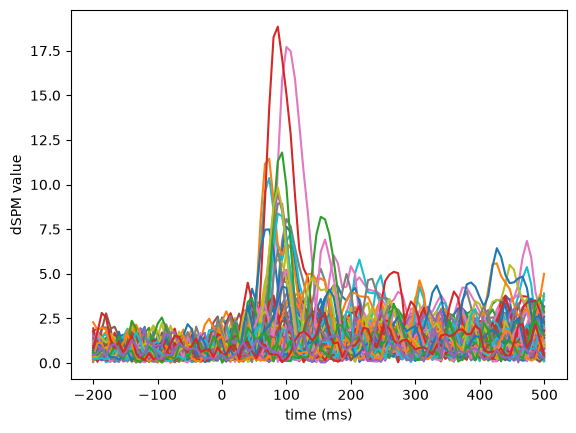

In [36]:
fig, ax = plt.subplots()
ax.plot(1e3 * stc.times, stc.data[::100, :].T)
ax.set(xlabel="time (ms)", ylabel=f"{method} value")

Examine the original data and the residual after fitting:



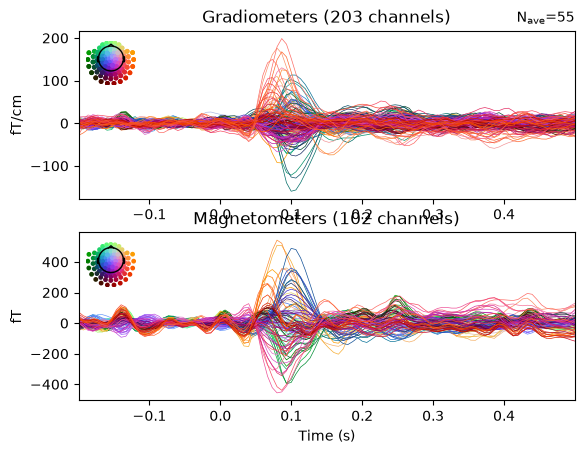

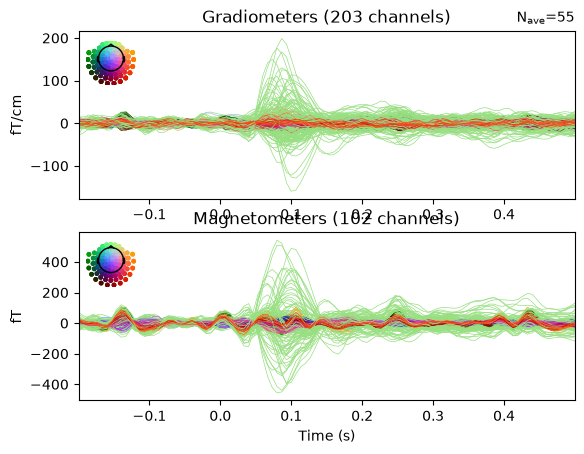

In [37]:
fig, axes = plt.subplots(2, 1)
evoked.plot(axes=axes)
for ax in axes:
    for text in list(ax.texts):
        text.remove()
    for line in ax.lines:
        line.set_color("#98df81")
residual.plot(axes=axes)

Here we use peak getter to move visualization to the time point of the peak
and draw a marker at the maximum peak vertex.



In [38]:
mne.viz.set_3d_backend("pyvistaqt")

subjects_dir = data_path / "subjects"

# Location (vertex) and time of the peak activation in the right hemisphere
vertno_max, time_max = stc.get_peak(hemi="rh")

# Color limits depend on the method
if method == "dSPM":
    # dSPM is noise-normalized (unitless), so the tutorial's fixed values work
    lims = [8, 12, 15]
else:
    # MNE / eLORETA (A·m) and sLORETA (normalized) have different scales, so
    # define the limits as fractions of the peak of the displayed hemisphere only
    # (using the whole stc would include the left hemisphere and inflate the range)
    peak_val = np.abs(stc.rh_data).max()
    lims = [0.3 * peak_val, 0.6 * peak_val, peak_val]  # lower fractions -> more area

brain = stc.plot(
    subject="sample",
    subjects_dir=subjects_dir,
    hemi="rh",
    views="lateral",
    initial_time=time_max,
    time_unit="s",
    clim=dict(kind="value", lims=lims),
    smoothing_steps=10,
    size=(800, 800),
)

# Mark the location of maximal activation
brain.add_foci(
    vertno_max,
    coords_as_verts=True,
    hemi="rh",
    color="blue",
    scale_factor=0.6,
    alpha=0.5,
)
brain.add_text(
    0.1, 0.9, f"{method} (plus location of maximal activation)", "title", font_size=14
)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


There are many other ways to visualize and work with source data, see
for example:

- `tut-viz-stcs`
- `ex-morph-surface`
- `ex-morph-volume`
- `ex-vector-mne-solution`
- `tut-dipole-orientations`
- `tut-mne-fixed-free`
- `examples using apply_inverse
  <sphx_glr_backreferences_mne.minimum_norm.apply_inverse>`.

